# Overfitting, Explained with Code

*By Shikha Pallavi*

A model can score perfectly on the data it studied and still fail on new data. That is **overfitting**. Here we see it happen, measure it, and fix it.

> ## 📖 Read the full series: [Machine Learning Basics](https://shikhapallavi123.github.io/ml-basics/)
> This notebook is the hands-on companion to **Part 2**. Read it first for the visual explanation, then run the code here.
> [Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html)

**What you'll learn**
1. Why we split data into train and test sets
2. What underfitting, a good fit and overfitting look like
3. How to spot overfitting from the numbers
4. One simple fix (regularization)

## 1. Make some data

We create 30 points that follow a smooth curve (a sine wave) plus random noise, like real-world measurements. Then we hold back a third of them as a **test set** the model never sees during training.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
X = np.sort(rng.uniform(0, 1, 30))
y = np.sin(2 * np.pi * X) + rng.normal(0, 0.25, size=30)   # true pattern + noise

X_train, X_test, y_train, y_test = train_test_split(
    X.reshape(-1, 1), y, test_size=1/3, random_state=0
)
print("train points:", len(X_train), "| test points:", len(X_test))

train points: 20 | test points: 10


## 2. Three models, three outcomes

We fit polynomials of different complexity (the *degree*):

- **Degree 1**: a straight line. Too simple.
- **Degree 3**: a gentle curve. About right.
- **Degree 15**: a very flexible curve. Too eager.

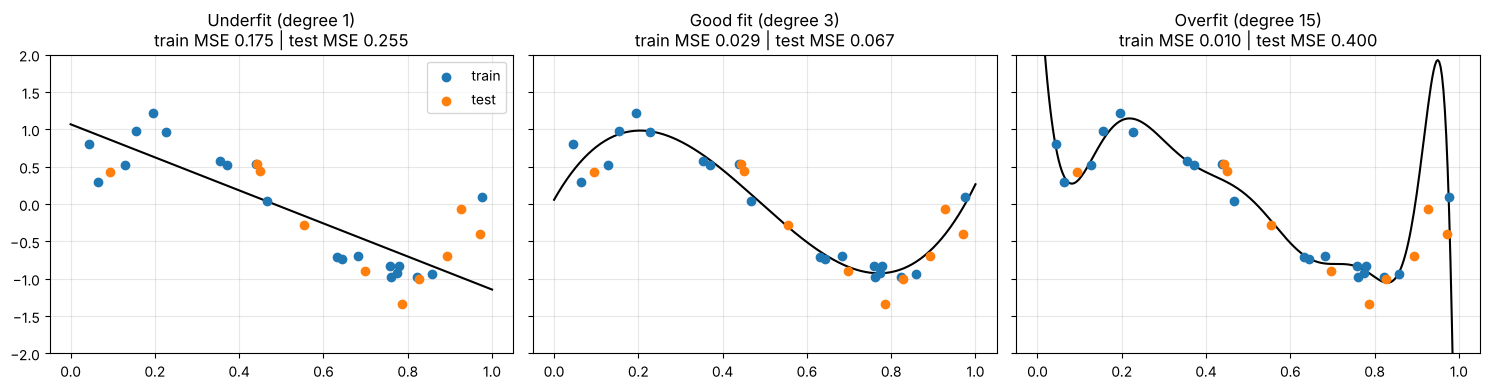

In [2]:
def fit_poly(degree, model=None):
    reg = model if model is not None else LinearRegression()
    pipe = make_pipeline(PolynomialFeatures(degree), StandardScaler(), reg)
    return pipe.fit(X_train, y_train)

grid = np.linspace(0, 1, 300).reshape(-1, 1)
cases = [(1, "Underfit (degree 1)"), (3, "Good fit (degree 3)"), (15, "Overfit (degree 15)")]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
rows = []
for ax, (deg, title) in zip(axes, cases):
    model = fit_poly(deg)
    tr = mean_squared_error(y_train, model.predict(X_train))
    te = mean_squared_error(y_test, model.predict(X_test))
    rows.append((title, tr, te))
    ax.scatter(X_train, y_train, color="tab:blue", label="train", zorder=3)
    ax.scatter(X_test, y_test, color="tab:orange", label="test", zorder=3)
    ax.plot(grid, np.clip(model.predict(grid), -2.5, 2.5), color="black")
    ax.set_title(f"{title}\ntrain MSE {tr:.3f} | test MSE {te:.3f}")
    ax.set_ylim(-2, 2)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

In [3]:
print(f"{'model':<24}{'train error':>14}{'test error':>14}")
for title, tr, te in rows:
    print(f"{title:<24}{tr:>14.3f}{te:>14.3f}")

model                      train error    test error
Underfit (degree 1)              0.175         0.255
Good fit (degree 3)              0.029         0.067
Overfit (degree 15)              0.010         0.400


Read the table like this:

- **Underfit:** error is high on both train and test. The model is too simple to see the pattern.
- **Good fit:** error is low and similar on both.
- **Overfit:** error on the training data is tiny, but on new data it is much worse. The model memorized the noise.

The warning sign is a **big gap** between train error and test error.

## 3. Watch the gap grow

Let's sweep the model complexity from degree 1 to 15 and plot both errors.

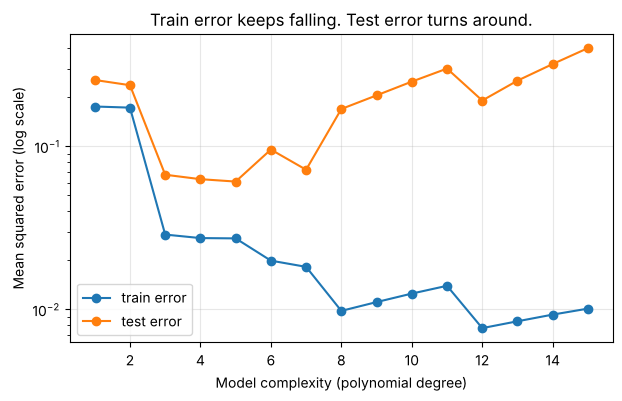

Degree with the lowest test error: 5


In [4]:
degrees = range(1, 16)
train_err, test_err = [], []
for d in degrees:
    model = fit_poly(d)
    train_err.append(mean_squared_error(y_train, model.predict(X_train)))
    test_err.append(mean_squared_error(y_test, model.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.plot(degrees, train_err, marker="o", label="train error", color="tab:blue")
plt.plot(degrees, test_err, marker="o", label="test error", color="tab:orange")
plt.yscale("log")
plt.xlabel("Model complexity (polynomial degree)")
plt.ylabel("Mean squared error (log scale)")
plt.title("Train error keeps falling. Test error turns around.")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best = list(degrees)[int(np.argmin(test_err))]
print("Degree with the lowest test error:", best)

Training error keeps going down as the model gets more flexible. Test error falls at first, then turns back up. The best model sits near the bottom of the test curve, not at the lowest training error.

## 4. One simple fix: regularization

**Ridge regression** adds a penalty for large coefficients, which stops a flexible model from chasing the noise. Same degree-15 model, with the penalty added:

Degree 15, no penalty    train 0.010 | test 0.400
Degree 15, Ridge         train 0.058 | test 0.110


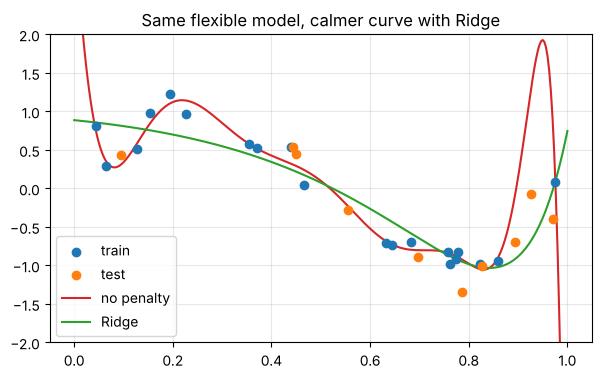

In [5]:
plain = fit_poly(15)
ridge = fit_poly(15, model=Ridge(alpha=1.0))

for name, mdl in [("Degree 15, no penalty", plain), ("Degree 15, Ridge", ridge)]:
    tr = mean_squared_error(y_train, mdl.predict(X_train))
    te = mean_squared_error(y_test, mdl.predict(X_test))
    print(f"{name:<24} train {tr:.3f} | test {te:.3f}")

plt.figure(figsize=(7, 4))
plt.scatter(X_train, y_train, color="tab:blue", label="train", zorder=3)
plt.scatter(X_test, y_test, color="tab:orange", label="test", zorder=3)
plt.plot(grid, np.clip(plain.predict(grid), -2.5, 2.5), color="tab:red", label="no penalty")
plt.plot(grid, ridge.predict(grid), color="tab:green", label="Ridge")
plt.ylim(-2, 2)
plt.legend()
plt.grid(alpha=0.3)
plt.title("Same flexible model, calmer curve with Ridge")
plt.show()

## Key takeaways

- Always keep a **test set** the model never trains on. It is your honest score.
- **Underfitting:** high error on train and test. **Overfitting:** low train error, high test error.
- A big **gap** between train and test error is the warning sign.
- More complex is not always better. Pick the model that does best on **new** data.
- **Regularization** (like Ridge) is one way to rein in a model that is too flexible.

## 📖 Continue the series
**[Read all of Machine Learning Basics →](https://shikhapallavi123.github.io/ml-basics/)**
[Part 1: Foundations](https://shikhapallavi123.github.io/ml-basics/part-1-foundations.html) · [Part 2: Supervised Learning](https://shikhapallavi123.github.io/ml-basics/part-2-supervised-learning.html) · [Part 3: Linear Regression](https://shikhapallavi123.github.io/ml-basics/part-3-linear-regression.html)

---
*© 2026 Shikha Pallavi. Shared under the Apache 2.0 license. You are welcome to reuse the code. Please credit the author and link back to the Machine Learning Basics series.*